# Machine Learning I - Actividad individual - Unidad 3

**Autor:** Jaime Alberto Chica Betancourt  
**Universidad:** Universidad de Investigación y Desarrollo - UDI  
**Programa:** Maestría en Ciencia de Datos e Inteligencia Artificial  
**Asignatura:** 7614 - Machine Learning I  
**Docente:** Jonathan Arley Monsalve Salazar  
**Fecha de entrega:** 7 de noviembre de 2026

## Objetivo

Aplicar y comparar técnicas de regresión polinomial, clustering y análisis de series temporales. El ejercicio utiliza datos sintéticos para estudiar relaciones no lineales, el conjunto *Mall Customers* para segmentación mediante K-Means y DBSCAN, y la serie *AirPassengers* para explorar tendencia, estacionalidad, autocorrelación, estacionariedad y pronóstico.

## 1. Librerías y configuración
Se importan las librerías utilizadas en el análisis y se definen valores comunes para reproducibilidad, partición de datos y nombres de archivos.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller


TEST_SIZE = 0.20
RANDOM_STATE = 42
from io import StringIO

MALL_CSV = 'CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)\n0001,Male,19,15,39\n0002,Male,21,15,81\n0003,Female,20,16,6\n0004,Female,23,16,77\n0005,Female,31,17,40\n0006,Female,22,17,76\n0007,Female,35,18,6\n0008,Female,23,18,94\n0009,Male,64,19,3\n0010,Female,30,19,72\n0011,Male,67,19,14\n0012,Female,35,19,99\n0013,Female,58,20,15\n0014,Female,24,20,77\n0015,Male,37,20,13\n0016,Male,22,20,79\n0017,Female,35,21,35\n0018,Male,20,21,66\n0019,Male,52,23,29\n0020,Female,35,23,98\n0021,Male,35,24,35\n0022,Male,25,24,73\n0023,Female,46,25,5\n0024,Male,31,25,73\n0025,Female,54,28,14\n0026,Male,29,28,82\n0027,Female,45,28,32\n0028,Male,35,28,61\n0029,Female,40,29,31\n0030,Female,23,29,87\n0031,Male,60,30,4\n0032,Female,21,30,73\n0033,Male,53,33,4\n0034,Male,18,33,92\n0035,Female,49,33,14\n0036,Female,21,33,81\n0037,Female,42,34,17\n0038,Female,30,34,73\n0039,Female,36,37,26\n0040,Female,20,37,75\n0041,Female,65,38,35\n0042,Male,24,38,92\n0043,Male,48,39,36\n0044,Female,31,39,61\n0045,Female,49,39,28\n0046,Female,24,39,65\n0047,Female,50,40,55\n0048,Female,27,40,47\n0049,Female,29,40,42\n0050,Female,31,40,42\n0051,Female,49,42,52\n0052,Male,33,42,60\n0053,Female,31,43,54\n0054,Male,59,43,60\n0055,Female,50,43,45\n0056,Male,47,43,41\n0057,Female,51,44,50\n0058,Male,69,44,46\n0059,Female,27,46,51\n0060,Male,53,46,46\n0061,Male,70,46,56\n0062,Male,19,46,55\n0063,Female,67,47,52\n0064,Female,54,47,59\n0065,Male,63,48,51\n0066,Male,18,48,59\n0067,Female,43,48,50\n0068,Female,68,48,48\n0069,Male,19,48,59\n0070,Female,32,48,47\n0071,Male,70,49,55\n0072,Female,47,49,42\n0073,Female,60,50,49\n0074,Female,60,50,56\n0075,Male,59,54,47\n0076,Male,26,54,54\n0077,Female,45,54,53\n0078,Male,40,54,48\n0079,Female,23,54,52\n0080,Female,49,54,42\n0081,Male,57,54,51\n0082,Male,38,54,55\n0083,Male,67,54,41\n0084,Female,46,54,44\n0085,Female,21,54,57\n0086,Male,48,54,46\n0087,Female,55,57,58\n0088,Female,22,57,55\n0089,Female,34,58,60\n0090,Female,50,58,46\n0091,Female,68,59,55\n0092,Male,18,59,41\n0093,Male,48,60,49\n0094,Female,40,60,40\n0095,Female,32,60,42\n0096,Male,24,60,52\n0097,Female,47,60,47\n0098,Female,27,60,50\n0099,Male,48,61,42\n0100,Male,20,61,49\n0101,Female,23,62,41\n0102,Female,49,62,48\n0103,Male,67,62,59\n0104,Male,26,62,55\n0105,Male,49,62,56\n0106,Female,21,62,42\n0107,Female,66,63,50\n0108,Male,54,63,46\n0109,Male,68,63,43\n0110,Male,66,63,48\n0111,Male,65,63,52\n0112,Female,19,63,54\n0113,Female,38,64,42\n0114,Male,19,64,46\n0115,Female,18,65,48\n0116,Female,19,65,50\n0117,Female,63,65,43\n0118,Female,49,65,59\n0119,Female,51,67,43\n0120,Female,50,67,57\n0121,Male,27,67,56\n0122,Female,38,67,40\n0123,Female,40,69,58\n0124,Male,39,69,91\n0125,Female,23,70,29\n0126,Female,31,70,77\n0127,Male,43,71,35\n0128,Male,40,71,95\n0129,Male,59,71,11\n0130,Male,38,71,75\n0131,Male,47,71,9\n0132,Male,39,71,75\n0133,Female,25,72,34\n0134,Female,31,72,71\n0135,Male,20,73,5\n0136,Female,29,73,88\n0137,Female,44,73,7\n0138,Male,32,73,73\n0139,Male,19,74,10\n0140,Female,35,74,72\n0141,Female,57,75,5\n0142,Male,32,75,93\n0143,Female,28,76,40\n0144,Female,32,76,87\n0145,Male,25,77,12\n0146,Male,28,77,97\n0147,Male,48,77,36\n0148,Female,32,77,74\n0149,Female,34,78,22\n0150,Male,34,78,90\n0151,Male,43,78,17\n0152,Male,39,78,88\n0153,Female,44,78,20\n0154,Female,38,78,76\n0155,Female,47,78,16\n0156,Female,27,78,89\n0157,Male,37,78,1\n0158,Female,30,78,78\n0159,Male,34,78,1\n0160,Female,30,78,73\n0161,Female,56,79,35\n0162,Female,29,79,83\n0163,Male,19,81,5\n0164,Female,31,81,93\n0165,Male,50,85,26\n0166,Female,36,85,75\n0167,Male,42,86,20\n0168,Female,33,86,95\n0169,Female,36,87,27\n0170,Male,32,87,63\n0171,Male,40,87,13\n0172,Male,28,87,75\n0173,Male,36,87,10\n0174,Male,36,87,92\n0175,Female,52,88,13\n0176,Female,30,88,86\n0177,Male,58,88,15\n0178,Male,27,88,69\n0179,Male,59,93,14\n0180,Male,35,93,90\n0181,Female,37,97,32\n0182,Female,32,97,86\n0183,Male,46,98,15\n0184,Female,29,98,88\n0185,Female,41,99,39\n0186,Male,30,99,97\n0187,Female,54,101,24\n0188,Male,28,101,68\n0189,Female,41,103,17\n0190,Female,36,103,85\n0191,Female,34,103,23\n0192,Female,32,103,69\n0193,Male,33,113,8\n0194,Female,38,113,91\n0195,Female,47,120,16\n0196,Female,35,120,79\n0197,Female,45,126,28\n0198,Male,32,126,74\n0199,Male,32,137,18\n0200,Male,30,137,83\n'

AIR_CSV = 'Month,#Passengers\n1949-01,112\n1949-02,118\n1949-03,132\n1949-04,129\n1949-05,121\n1949-06,135\n1949-07,148\n1949-08,148\n1949-09,136\n1949-10,119\n1949-11,104\n1949-12,118\n1950-01,115\n1950-02,126\n1950-03,141\n1950-04,135\n1950-05,125\n1950-06,149\n1950-07,170\n1950-08,170\n1950-09,158\n1950-10,133\n1950-11,114\n1950-12,140\n1951-01,145\n1951-02,150\n1951-03,178\n1951-04,163\n1951-05,172\n1951-06,178\n1951-07,199\n1951-08,199\n1951-09,184\n1951-10,162\n1951-11,146\n1951-12,166\n1952-01,171\n1952-02,180\n1952-03,193\n1952-04,181\n1952-05,183\n1952-06,218\n1952-07,230\n1952-08,242\n1952-09,209\n1952-10,191\n1952-11,172\n1952-12,194\n1953-01,196\n1953-02,196\n1953-03,236\n1953-04,235\n1953-05,229\n1953-06,243\n1953-07,264\n1953-08,272\n1953-09,237\n1953-10,211\n1953-11,180\n1953-12,201\n1954-01,204\n1954-02,188\n1954-03,235\n1954-04,227\n1954-05,234\n1954-06,264\n1954-07,302\n1954-08,293\n1954-09,259\n1954-10,229\n1954-11,203\n1954-12,229\n1955-01,242\n1955-02,233\n1955-03,267\n1955-04,269\n1955-05,270\n1955-06,315\n1955-07,364\n1955-08,347\n1955-09,312\n1955-10,274\n1955-11,237\n1955-12,278\n1956-01,284\n1956-02,277\n1956-03,317\n1956-04,313\n1956-05,318\n1956-06,374\n1956-07,413\n1956-08,405\n1956-09,355\n1956-10,306\n1956-11,271\n1956-12,306\n1957-01,315\n1957-02,301\n1957-03,356\n1957-04,348\n1957-05,355\n1957-06,422\n1957-07,465\n1957-08,467\n1957-09,404\n1957-10,347\n1957-11,305\n1957-12,336\n1958-01,340\n1958-02,318\n1958-03,362\n1958-04,348\n1958-05,363\n1958-06,435\n1958-07,491\n1958-08,505\n1958-09,404\n1958-10,359\n1958-11,310\n1958-12,337\n1959-01,360\n1959-02,342\n1959-03,406\n1959-04,396\n1959-05,420\n1959-06,472\n1959-07,548\n1959-08,559\n1959-09,463\n1959-10,407\n1959-11,362\n1959-12,405\n1960-01,417\n1960-02,391\n1960-03,419\n1960-04,461\n1960-05,472\n1960-06,535\n1960-07,622\n1960-08,606\n1960-09,508\n1960-10,461\n1960-11,390\n1960-12,432\n'


## 2. Regresión polinomial

Se genera un conjunto sintético de 200 observaciones con una relación cúbica y ruido aleatorio. La relación no lineal se define explícitamente para poder comparar un modelo lineal con regresiones polinomiales de grados 2 y 3. Los datos se dividen en 80 % para entrenamiento y 20 % para prueba.

In [2]:
def create_nonlinear_dataset():

    """
    Genera datos sintéticos con una relación cúbica y ruido aleatorio.
    """

    # Crea un generador aleatorio reproducible
    rng = np.random.default_rng(RANDOM_STATE)

    # Genera 200 valores de X distribuidos entre -3 y 3
    X = rng.uniform(-3, 3, size=200).reshape(-1, 1)

    # Genera ruido aleatorio para simular variabilidad en los datos
    noise = rng.normal(0, 3, size=200)

    # Genera y mediante una relación cúbica con X y añade el ruido
    y = (
        4
        + 2 * X[:, 0]
        - 1.5 * X[:, 0] ** 2
        + 0.8 * X[:, 0] ** 3
        + noise
    )

    return X, y

def train_regression_models(X_train, y_train):

    """
    Entrena modelos lineal y polinomial de grados 2 y 3
    """

    # Define los tres modelos que serán comparados: regresión lineal y regresiones polinomiales de grados 2 y 3
    models = {
        "Lineal": LinearRegression(),

        # Genera X y X² antes de aplicar la regresión lineal
        "Polinomial grado 2": Pipeline([
            ("polynomial_features", PolynomialFeatures(degree=2, include_bias=False)),
            ("linear_regression", LinearRegression()),
        ]),

        # Genera X, X² y X³ antes de aplicar la regresión lineal
        "Polinomial grado 3": Pipeline([
            ("polynomial_features", PolynomialFeatures(degree=3, include_bias=False)),
            ("linear_regression", LinearRegression()),
        ]),
    }

    # Entrena los tres modelos utilizando los mismos datos
    for model in models.values():
        model.fit(X_train, y_train)

    return models

def evaluate_regression_models(models, X_train, X_test, y_train, y_test):

    """
    Calcula MSE y R2 de entrenamiento y prueba para cada modelo
    """

    rows = []

    # Genera predicciones y calcula las métricas de entrenamiento y prueba para cada modelo
    for model_name, model in models.items():
        train_prediction = model.predict(X_train)
        test_prediction = model.predict(X_test)

        rows.append({
            "Modelo": model_name,
            "MSE entrenamiento": mean_squared_error(y_train, train_prediction),
            "MSE prueba": mean_squared_error(y_test, test_prediction),
            "R2 entrenamiento": r2_score(y_train, train_prediction),
            "R2 prueba": r2_score(y_test, test_prediction),
        })

    # Convierte los resultados en una tabla para facilitar la comparación
    results = pd.DataFrame(rows)
    print("\nREGRESIÓN: COMPARACIÓN DE MODELOS")
    print("=" * 90)
    print(results.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
    return results

def plot_regression_fits(X, y, models):

    """
    Grafica los datos y las curvas ajustadas por los tres modelos
    """

    # Genera 500 valores ordenados de X para dibujar de forma continua las curvas de los modelos
    X_plot = np.linspace(X.min(), X.max(), 500).reshape(-1, 1)
    plt.figure(figsize=(10, 6))
    plt.scatter(X[:, 0], y, alpha=0.45, label="Datos con ruido")

    # Genera y grafica las predicciones de cada modelo sobre los mismos valores de X
    for model_name, model in models.items():
        plt.plot(X_plot[:, 0], model.predict(X_plot), linewidth=2, label=model_name)

    plt.title("Comparación del ajuste lineal y polinomial")
    plt.xlabel("Variable predictora X")
    plt.ylabel("Variable objetivo y")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("regression_fits.png", dpi=300, bbox_inches="tight")
    plt.close()

def run_polynomial_regression():

    """
    Ejecuta el análisis completo de regresión polinomial
    """

    # Genera el conjunto de datos sintético con relación no lineal
    X, y = create_nonlinear_dataset()

    # Divide los datos en conjuntos de entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,)

    # Entrena los modelos lineal y polinomiales de grados 2 y 3
    models = train_regression_models(X_train, y_train)

    # Evalúa y compara los modelos mediante MSE y R²
    results = evaluate_regression_models(models, X_train, X_test, y_train, y_test)
    plot_regression_fits(X, y, models)

    return {"models": models, "results": results}

In [3]:
regression_results = run_polynomial_regression()
regression_results["results"]


REGRESIÓN: COMPARACIÓN DE MODELOS
            Modelo  MSE entrenamiento  MSE prueba  R2 entrenamiento  R2 prueba
            Lineal            30.1232     35.6318            0.7995     0.7741
Polinomial grado 2            17.4321     13.8945            0.8840     0.9119
Polinomial grado 3             8.9368      9.1621            0.9405     0.9419


,Modelo,MSE entrenamiento,MSE prueba,R2 entrenamiento,R2 prueba
0,Lineal,30.123168,35.631787,0.799526,0.774117
1,Polinomial grado 2,17.432129,13.894469,0.883986,0.911918
2,Polinomial grado 3,8.936849,9.162105,0.940524,0.941918


### Interpretación
El MSE permite comparar el error de predicción, mientras que R² permite evaluar qué proporción de la variabilidad es representada por el modelo. La comparación entre entrenamiento y prueba también permite detectar posibles señales de sobreajuste. La visualización facilita observar cómo los modelos polinomiales siguen una relación curva que el modelo lineal no puede representar con la misma flexibilidad.

,Modelo,MSE entrenamiento,MSE prueba,R2 entrenamiento,R2 prueba
0,Lineal,30.123168,35.631787,0.799526,0.774117
1,Polinomial grado 2,17.432129,13.894469,0.883986,0.911918
2,Polinomial grado 3,8.936849,9.162105,0.940524,0.941918


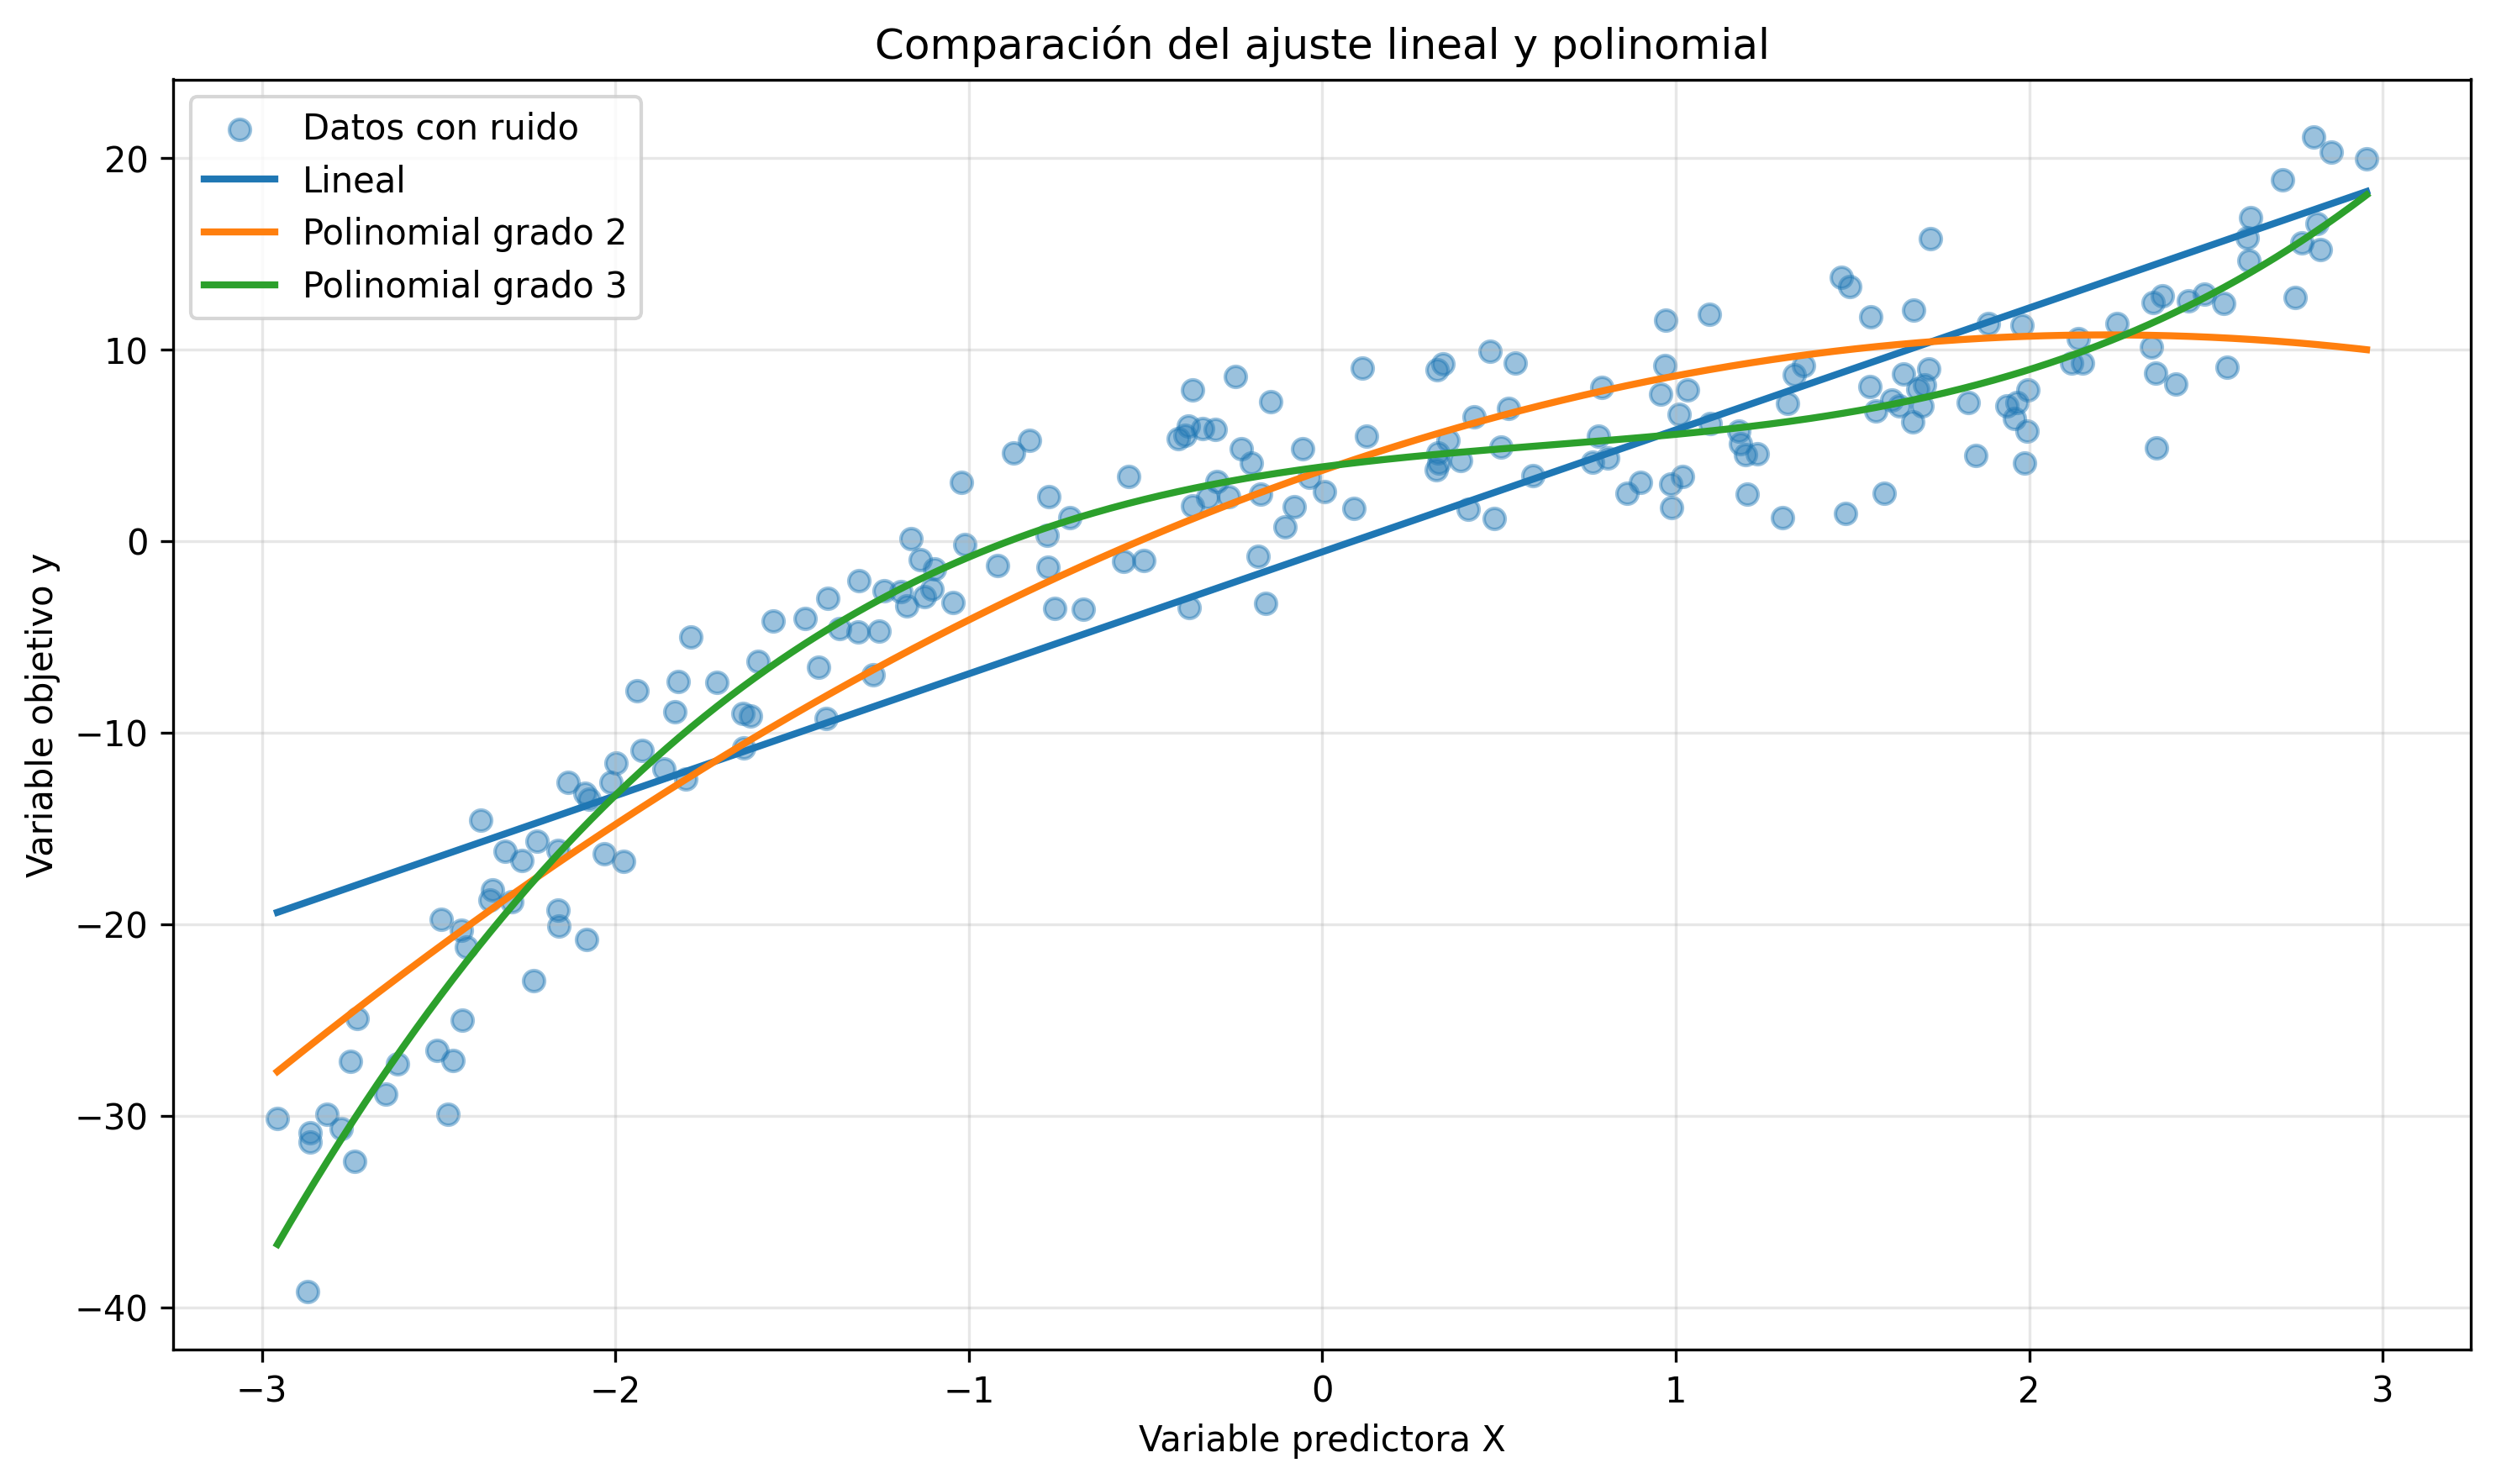

In [4]:
from IPython.display import display
display(regression_results["results"])
from IPython.display import Image
display(Image(filename="regression_fits.png"))

## 3. Clustering

Se emplean las variables `Annual Income (k$)` y `Spending Score (1-100)` del conjunto *Mall Customers* incorporado en el Notebook. Antes de aplicar los algoritmos, las dos variables se estandarizan mediante `StandardScaler`. Para K-Means se comparan valores de `k` entre 2 y 10 mediante inercia y coeficiente de silueta; luego se compara la solución seleccionada con DBSCAN.

In [5]:
def load_mall_data():

    """
    Carga el dataset Mall Customers incorporado en el Notebook.
    """

    data = pd.read_csv(StringIO(MALL_CSV), dtype={"CustomerID": str})
    print("\nMALL CUSTOMERS")
    print("=" * 90)
    print(f"Observaciones: {data.shape[0]}")
    print(f"Variables: {data.shape[1]}")
    print(f"Valores faltantes: {int(data.isna().sum().sum())}")
    return data


def prepare_clustering_data(data):

    """
    Selecciona ingreso y puntuación de gasto y los estandariza
    """

    feature_names = ["Annual Income (k$)", "Spending Score (1-100)"]
    X = data[feature_names]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    return X, X_scaled, scaler

def find_optimal_k(X_scaled):

    """
    Evalúa K-Means con el método del codo y el coeficiente de silueta
    """

    # Evalúa soluciones entre 2 y 10 clusters
    k_values = range(2, 11)
    inertia_values = []
    silhouette_values = []

    # Entrena K-Means para cada valor de k y almacena la inercia y el coeficiente de silueta obtenidos
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = model.fit_predict(X_scaled)
        inertia_values.append(model.inertia_)
        silhouette_values.append(silhouette_score(X_scaled, labels))

    # Selecciona el número de clusters con mayor coeficiente de silueta
    best_k = list(k_values)[int(np.argmax(silhouette_values))]

    # Organiza los resultados para facilitar su comparación
    results = pd.DataFrame({"k": list(k_values), "Inercia": inertia_values, "Silueta": silhouette_values,})

    print("\nK-MEANS: EVALUACIÓN DEL NÚMERO DE CLUSTERS")
    print("=" * 90)
    print(results.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
    print(f"\nNúmero de clusters seleccionado por silueta: {best_k}")

    # Grafica el método del codo y el coeficiente de silueta
    figure, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].plot(list(k_values), inertia_values, marker="o")
    axes[0].set_title("Método del codo")
    axes[0].set_xlabel("Número de clusters (k)")
    axes[0].set_ylabel("Inercia")
    axes[0].grid(alpha=0.3)

    axes[1].plot(list(k_values), silhouette_values, marker="o")
    axes[1].axvline(best_k, linestyle="--", color="red", label=f"Mejor k = {best_k}")
    axes[1].set_title("Coeficiente de silueta")
    axes[1].set_xlabel("Número de clusters (k)")
    axes[1].set_ylabel("Silueta")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig("clustering_k_selection.png", dpi=300, bbox_inches="tight")
    plt.close()

    return best_k, results

def fit_clustering_models(X_scaled, best_k):

    """
    Entrena K-Means y DBSCAN sobre las variables estandarizadas
    """

    # Entrena K-Means utilizando el número de clusters seleccionado previamente mediante el coeficiente de silueta
    kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
    kmeans_labels = kmeans.fit_predict(X_scaled)

    # Entrena DBSCAN utilizando valores iniciales de distancia máxima entre vecinos (eps) y número mínimo de observaciones (min_samples)
    dbscan = DBSCAN(eps=0.35, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_scaled)

    # Cuenta los clusters identificados por DBSCAN, excluyendo la etiqueta -1 correspondiente al ruido
    n_dbscan_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

    # Cuenta las observaciones identificadas como ruido
    n_noise = int(np.sum(dbscan_labels == -1))

    print("\nRESULTADOS DE CLUSTERING")
    print("=" * 90)
    print(f"Clusters K-Means: {len(np.unique(kmeans_labels))}")
    print(f"Clusters DBSCAN: {n_dbscan_clusters}")
    print(f"Observaciones identificadas como ruido por DBSCAN: {n_noise}")

    return {
        "kmeans": kmeans,
        "kmeans_labels": kmeans_labels,
        "dbscan": dbscan,
        "dbscan_labels": dbscan_labels,
        "dbscan_clusters": n_dbscan_clusters,
        "dbscan_noise": n_noise,
    }

def plot_clusters(X, clustering_results):

    """
    Visualiza en 2D los clusters obtenidos por K-Means y DBSCAN
    """

    figure, axes = plt.subplots(1, 2, figsize=(14, 6))

    sns.scatterplot(
        x=X.iloc[:, 0],
        y=X.iloc[:, 1],
        hue=clustering_results["kmeans_labels"],
        palette="tab10",
        ax=axes[0],
        legend="full",
    )
    axes[0].set_title("Clusters con K-Means")
    axes[0].set_xlabel("Ingreso anual (k$)")
    axes[0].set_ylabel("Puntuación de gasto")

    sns.scatterplot(
        x=X.iloc[:, 0],
        y=X.iloc[:, 1],
        hue=clustering_results["dbscan_labels"],
        palette="tab10",
        ax=axes[1],
        legend="full",
    )
    axes[1].set_title("Clusters con DBSCAN (-1 = ruido)")
    axes[1].set_xlabel("Ingreso anual (k$)")
    axes[1].set_ylabel("Puntuación de gasto")

    plt.tight_layout()
    plt.savefig("clustering_comparison.png", dpi=300, bbox_inches="tight")
    plt.close()

def run_clustering():

    """
    Ejecuta el análisis completo de clustering
    """

    # Carga el dataset Mall Customers
    data = load_mall_data()

    # Selecciona las variables de ingreso y gasto y las estandariza
    X, X_scaled, scaler = prepare_clustering_data(data)

    # Evalúa diferentes valores de k y selecciona el mejor mediante el coeficiente de silueta
    best_k, k_results = find_optimal_k(X_scaled)

    # Entrena K-Means con el k seleccionado y DBSCAN sobre los mismos datos estandarizados
    clustering_results = fit_clustering_models(X_scaled, best_k)

    # Compara visualmente los clusters obtenidos por ambos métodos
    plot_clusters(X, clustering_results)

    return {
        "data": data,
        "scaler": scaler,
        "k_results": k_results,
        **clustering_results,
    }

In [6]:
clustering_results = run_clustering()
clustering_results["k_results"]


MALL CUSTOMERS
Observaciones: 200
Variables: 5
Valores faltantes: 0

K-MEANS: EVALUACIÓN DEL NÚMERO DE CLUSTERS
 k  Inercia  Silueta
 2 269.6910   0.3213
 3 157.7040   0.4666
 4 108.9213   0.4939
 5  65.5684   0.5547
 6  55.0573   0.5399
 7  44.8648   0.5281
 8  37.2282   0.4552
 9  32.3923   0.4571
10  29.9819   0.4432

Número de clusters seleccionado por silueta: 5

RESULTADOS DE CLUSTERING
Clusters K-Means: 5
Clusters DBSCAN: 6
Observaciones identificadas como ruido por DBSCAN: 23


,k,Inercia,Silueta
0,2,269.691012,0.321271
1,3,157.704008,0.466585
2,4,108.921317,0.493907
3,5,65.568408,0.554657
4,6,55.057348,0.539880
5,7,44.864756,0.528149
6,8,37.228188,0.455215
7,9,32.392268,0.457085
8,10,29.981898,0.443171


### Selección del número de clusters
La inercia es la base del método del codo: se busca el punto a partir del cual aumentar `k` produce reducciones cada vez menores. El coeficiente de silueta aporta una medida complementaria de cohesión y separación de los grupos. En este conjunto ambos análisis apoyan una solución alrededor de cinco grupos, y el valor máximo de silueta se utiliza para seleccionar `k` en el script.

,k,Inercia,Silueta
0,2,269.691012,0.321271
1,3,157.704008,0.466585
2,4,108.921317,0.493907
3,5,65.568408,0.554657
4,6,55.057348,0.539880
5,7,44.864756,0.528149
6,8,37.228188,0.455215
7,9,32.392268,0.457085
8,10,29.981898,0.443171


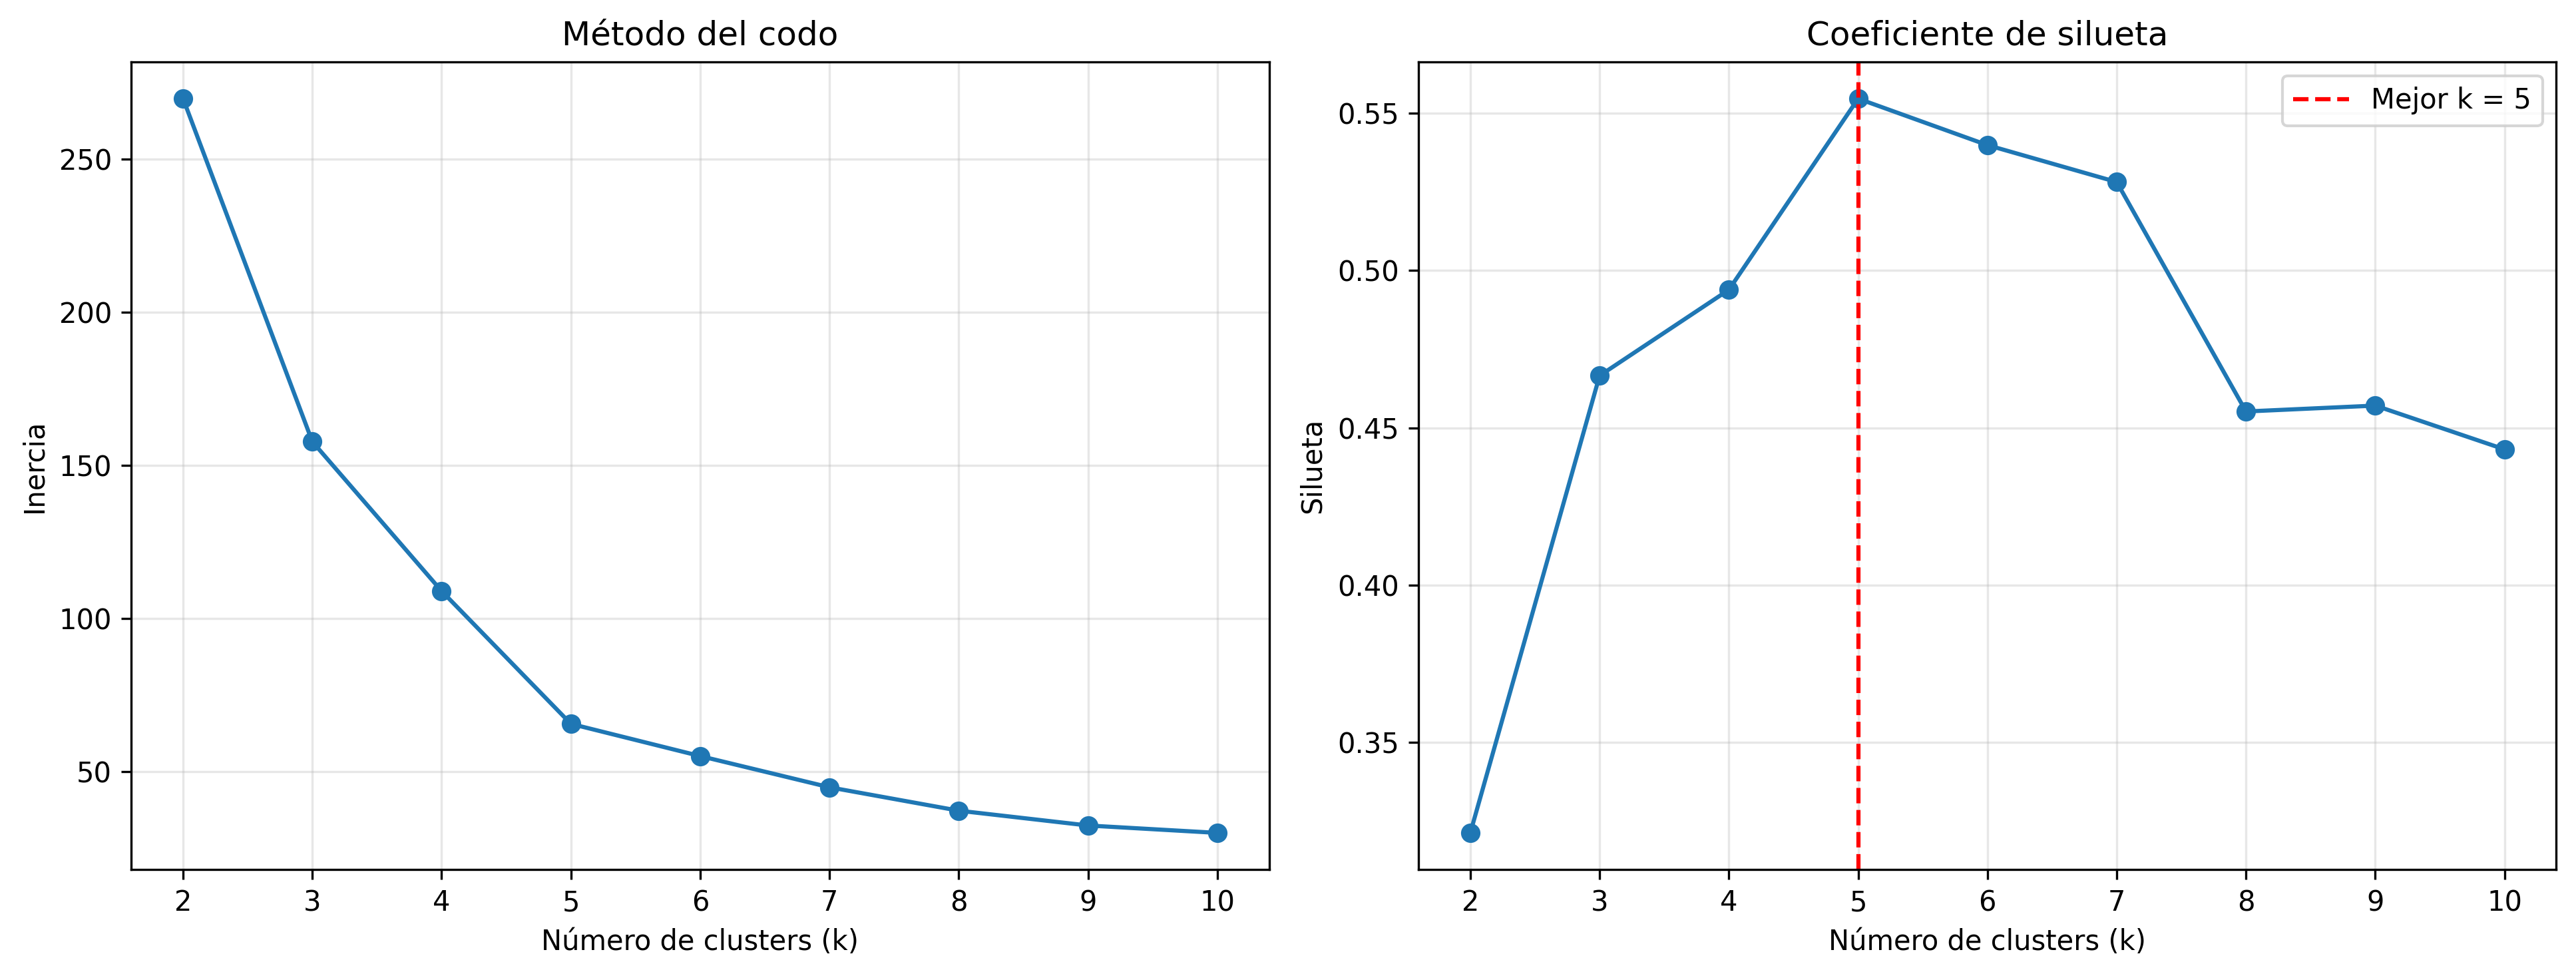

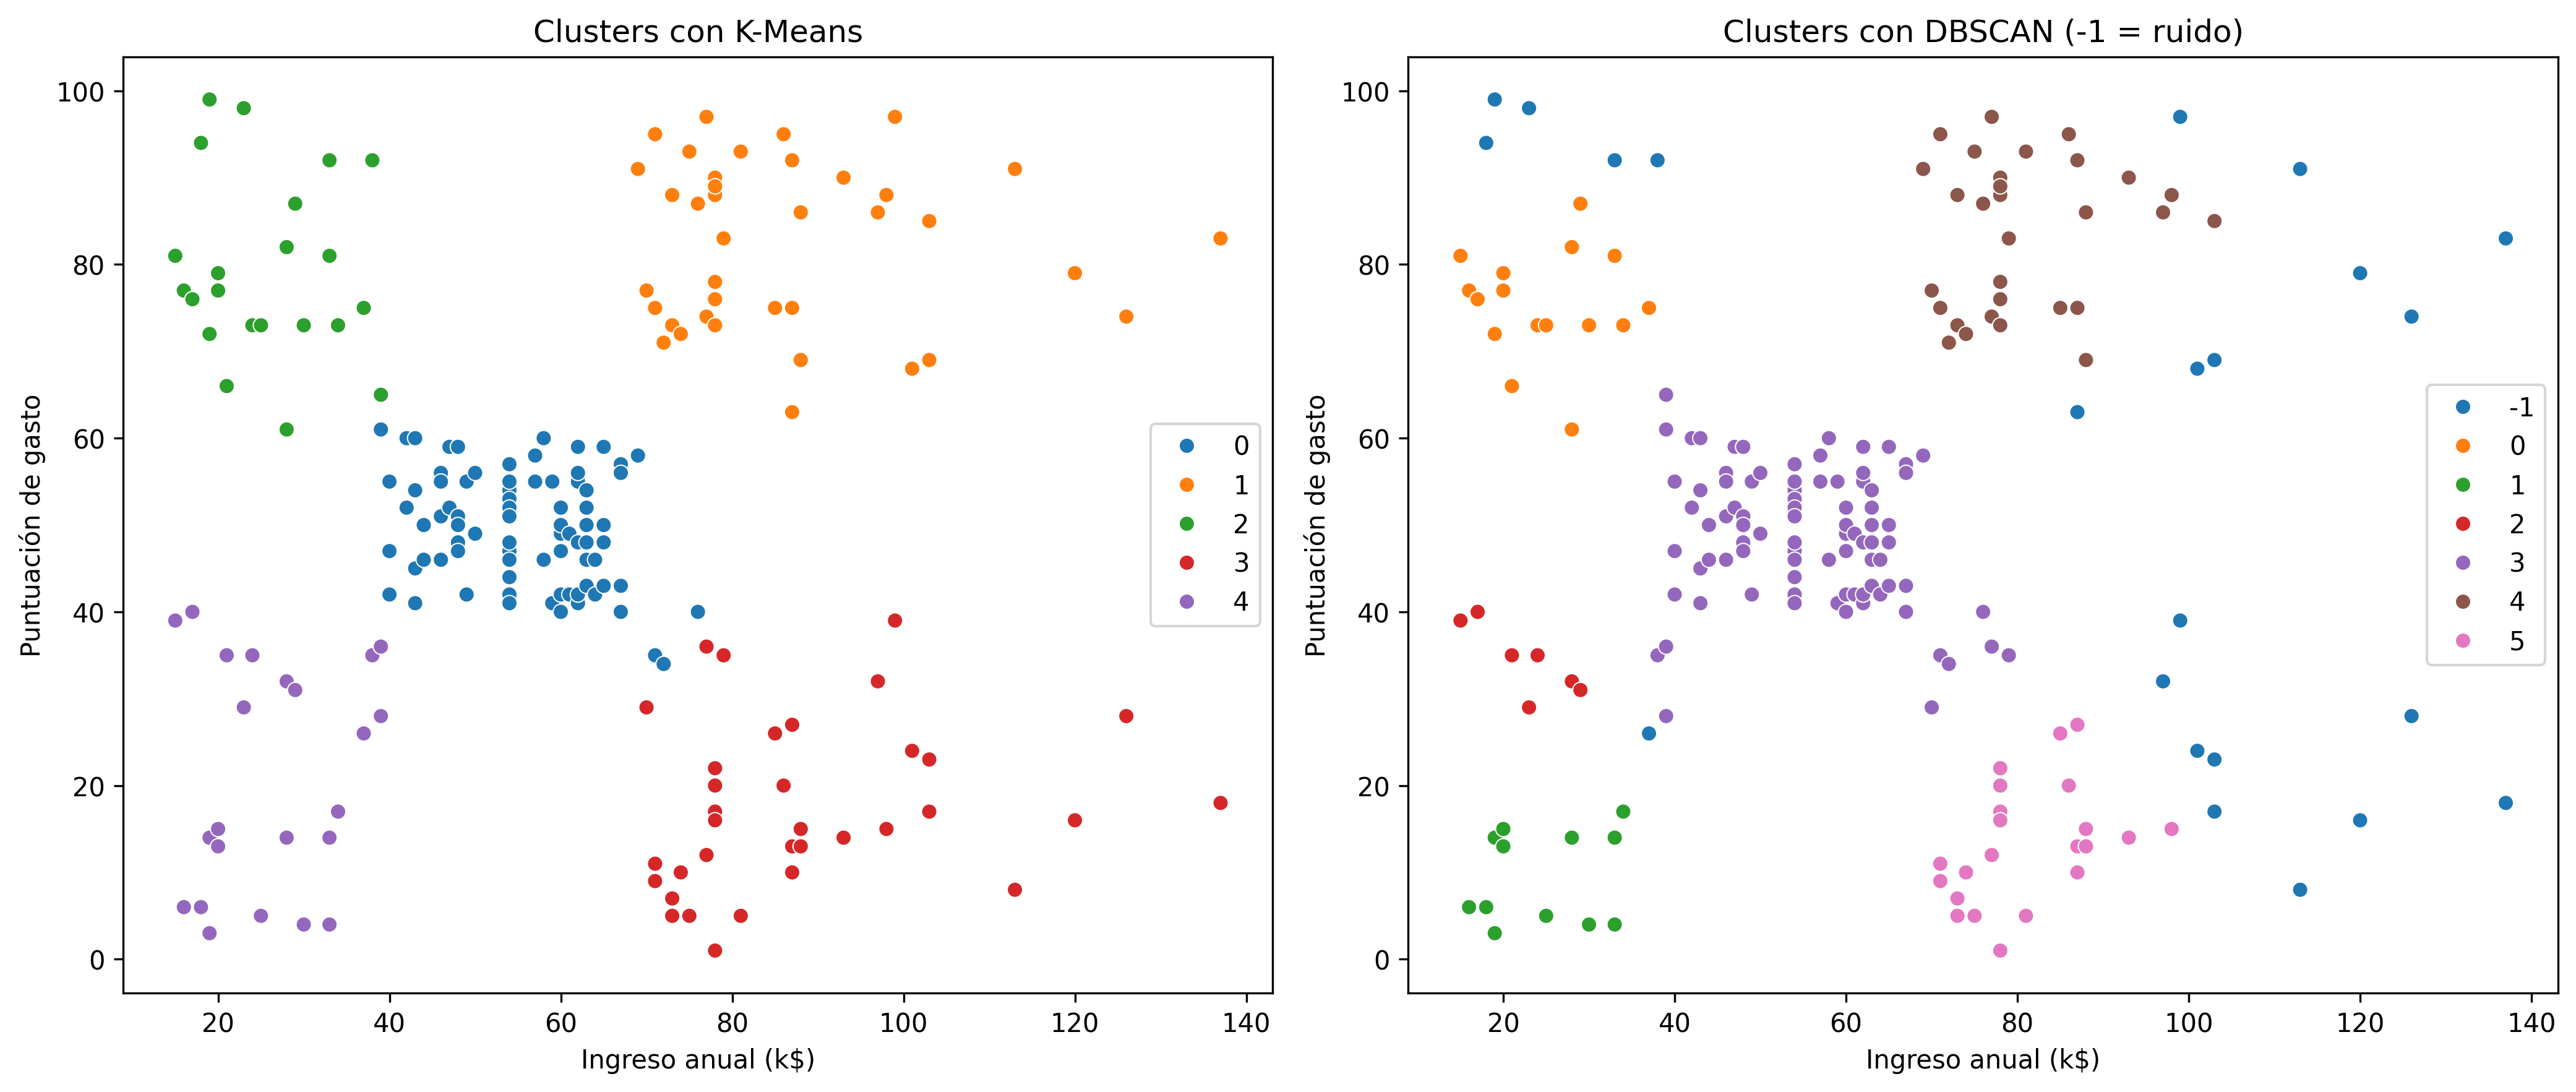

In [7]:
from IPython.display import display, Image
display(clustering_results["k_results"])
display(Image(filename="clustering_k_selection.png"))
display(Image(filename="clustering_comparison.png"))

### Comparación K-Means y DBSCAN
K-Means requiere especificar previamente el número de grupos y asigna todas las observaciones a un cluster. DBSCAN identifica regiones según densidad, no necesita recibir previamente el número de clusters y puede separar observaciones como ruido. Por ello, ambas técnicas pueden producir estructuras diferentes aun trabajando sobre las mismas variables estandarizadas.

## 4. Análisis de series de tiempo

Se utiliza la serie *AirPassengers* incorporada en el Notebook, una serie mensual de pasajeros aéreos. El análisis incluye medias móviles, autocorrelación, descomposición multiplicativa con periodo anual, prueba Augmented Dickey-Fuller y un pronóstico Holt-Winters evaluado sobre los últimos 24 meses.

In [8]:
def load_air_passengers():

    """
    Carga AirPassengers incorporado en el Notebook y configura la fecha como índice mensual.
    """

    data = pd.read_csv(StringIO(AIR_CSV))
    data["Month"] = pd.to_datetime(data["Month"])
    data = data.set_index("Month").asfreq("MS")
    series = data["#Passengers"].astype(float)

    print("\nAIR PASSENGERS")
    print("=" * 90)
    print(f"Observaciones mensuales: {len(series)}")
    print(f"Valores faltantes: {int(series.isna().sum())}")
    print(f"Periodo: {series.index.min().date()} a {series.index.max().date()}")
    return series


def plot_time_series(series):

    """
    Grafica la serie original y sus medias móviles de 6 y 12 meses
    """

    plt.figure(figsize=(12, 6))
    plt.plot(series, label="Pasajeros mensuales", linewidth=1.8)
    plt.plot(series.rolling(6).mean(), label="Media móvil 6 meses")
    plt.plot(series.rolling(12).mean(), label="Media móvil 12 meses")
    plt.title("AirPassengers: serie y medias móviles")
    plt.xlabel("Fecha")
    plt.ylabel("Número de pasajeros")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("time_series_moving_average.png", dpi=300, bbox_inches="tight")
    plt.close()

def analyze_time_series(series):

    """
    Genera autocorrelación, descomposición y prueba ADF
    """

    figure, axis = plt.subplots(figsize=(10, 5))
    plot_acf(series, lags=36, ax=axis)
    axis.set_title("Autocorrelación de AirPassengers")
    axis.set_xlabel("Retardo (meses)")
    axis.set_ylabel("Autocorrelación")
    plt.tight_layout()
    plt.savefig("time_series_autocorrelation.png", dpi=300, bbox_inches="tight")
    plt.close()


    # Descompone la serie en tendencia, estacionalidad y residuos, utilizando un ciclo estacional de 12 meses
    decomposition = seasonal_decompose(series, model="multiplicative", period=12)

    decomposition_figure = decomposition.plot()
    decomposition_figure.set_size_inches(12, 9)
    decomposition_figure.tight_layout()
    decomposition_figure.savefig("time_series_decomposition.png", dpi=300, bbox_inches="tight",)
    plt.close(decomposition_figure)

    # Aplica la prueba ADF para evaluar si la serie es estacionaria
    adf_statistic, p_value, _, _, critical_values, _ = adfuller(series, result_object=False)

    print("\nPRUEBA DE DICKEY-FULLER AUMENTADA")
    print("=" * 90)
    print(f"Estadístico ADF: {adf_statistic:.4f}")
    print(f"Valor p: {p_value:.4f}")
    for level, value in critical_values.items():
        print(f"Valor crítico {level}: {value:.4f}")

    # Con alfa = 0,05, un valor p menor a 0,05 permite considerar la serie estacionaria
    stationarity = "estacionaria" if p_value < 0.05 else "no estacionaria"
    print(f"Conclusión con alfa=0.05: la serie es {stationarity}.")

    return {
        "decomposition": decomposition,
        "adf_statistic": adf_statistic,
        "p_value": p_value,
        "stationarity": stationarity,
    }

def forecast_time_series(series, test_months=24):

    """
    Pronostica los últimos meses mediante Holt-Winters con tendencia aditiva y estacionalidad multiplicativa
    """

    # Utiliza los últimos 24 meses como conjunto de prueba y todos los meses anteriores como entrenamiento
    train = series.iloc[:-test_months]
    test = series.iloc[-test_months:]

    # Entrena Holt-Winters considerando tendencia creciente y un patrón estacional que se repite cada 12 meses
    model = ExponentialSmoothing(
        train,
        trend="add",
        seasonal="mul",
        seasonal_periods=12,
        initialization_method="estimated",
    ).fit(optimized=True)

    # Pronostica los meses reservados para prueba
    forecast = model.forecast(test_months)

    # Compara el pronóstico con los valores reales
    mse = mean_squared_error(test, forecast)
    r2 = r2_score(test, forecast)

    print("\nPRONÓSTICO HOLT-WINTERS")
    print("=" * 90)
    print(f"Meses pronosticados: {test_months}")
    print(f"MSE de prueba: {mse:.4f}")
    print(f"R2 de prueba: {r2:.4f}")

    # Compara visualmente entrenamiento, valores reales y pronóstico del modelo
    plt.figure(figsize=(12, 6))
    plt.plot(train, label="Entrenamiento")
    plt.plot(test, label="Valores reales", linewidth=2)
    plt.plot(forecast, label="Pronóstico Holt-Winters", linestyle="--", linewidth=2)
    plt.title("Pronóstico de pasajeros aéreos")
    plt.xlabel("Fecha")
    plt.ylabel("Número de pasajeros")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("time_series_forecast.png", dpi=300, bbox_inches="tight")
    plt.close()

    return {
        "model": model,
        "train": train,
        "test": test,
        "forecast": forecast,
        "mse": mse,
        "r2": r2,
    }

def run_time_series():

    """
    Ejecuta el análisis completo de la serie temporal
    """

    # Carga la serie temporal AirPassengers
    series = load_air_passengers()

    # Grafica la serie original y sus medias móviles
    plot_time_series(series)

    # Analiza autocorrelación, tendencia, estacionalidad y estacionariedad de la serie
    analysis = analyze_time_series(series)

    # Entrena Holt-Winters y evalúa el pronóstico utilizando los últimos 24 meses como prueba
    forecast = forecast_time_series(series)

    return {"series": series, "analysis": analysis, "forecast": forecast}

In [9]:
time_series_results = run_time_series()


AIR PASSENGERS
Observaciones mensuales: 144
Valores faltantes: 0
Periodo: 1949-01-01 a 1960-12-01

PRUEBA DE DICKEY-FULLER AUMENTADA
Estadístico ADF: 0.8154
Valor p: 0.9919
Valor crítico 1%: -3.4817
Valor crítico 5%: -2.8840
Valor crítico 10%: -2.5788
Conclusión con alfa=0.05: la serie es no estacionaria.

PRONÓSTICO HOLT-WINTERS
Meses pronosticados: 24
MSE de prueba: 1055.5099
R2 de prueba: 0.8107


### Tendencia, estacionalidad y autocorrelación
La serie muestra crecimiento de largo plazo y un patrón estacional recurrente. Las medias móviles facilitan observar la tendencia. La autocorrelación permite estudiar la relación entre cada observación y valores anteriores, mientras que la descomposición separa el comportamiento observado en tendencia, estacionalidad y componente residual.

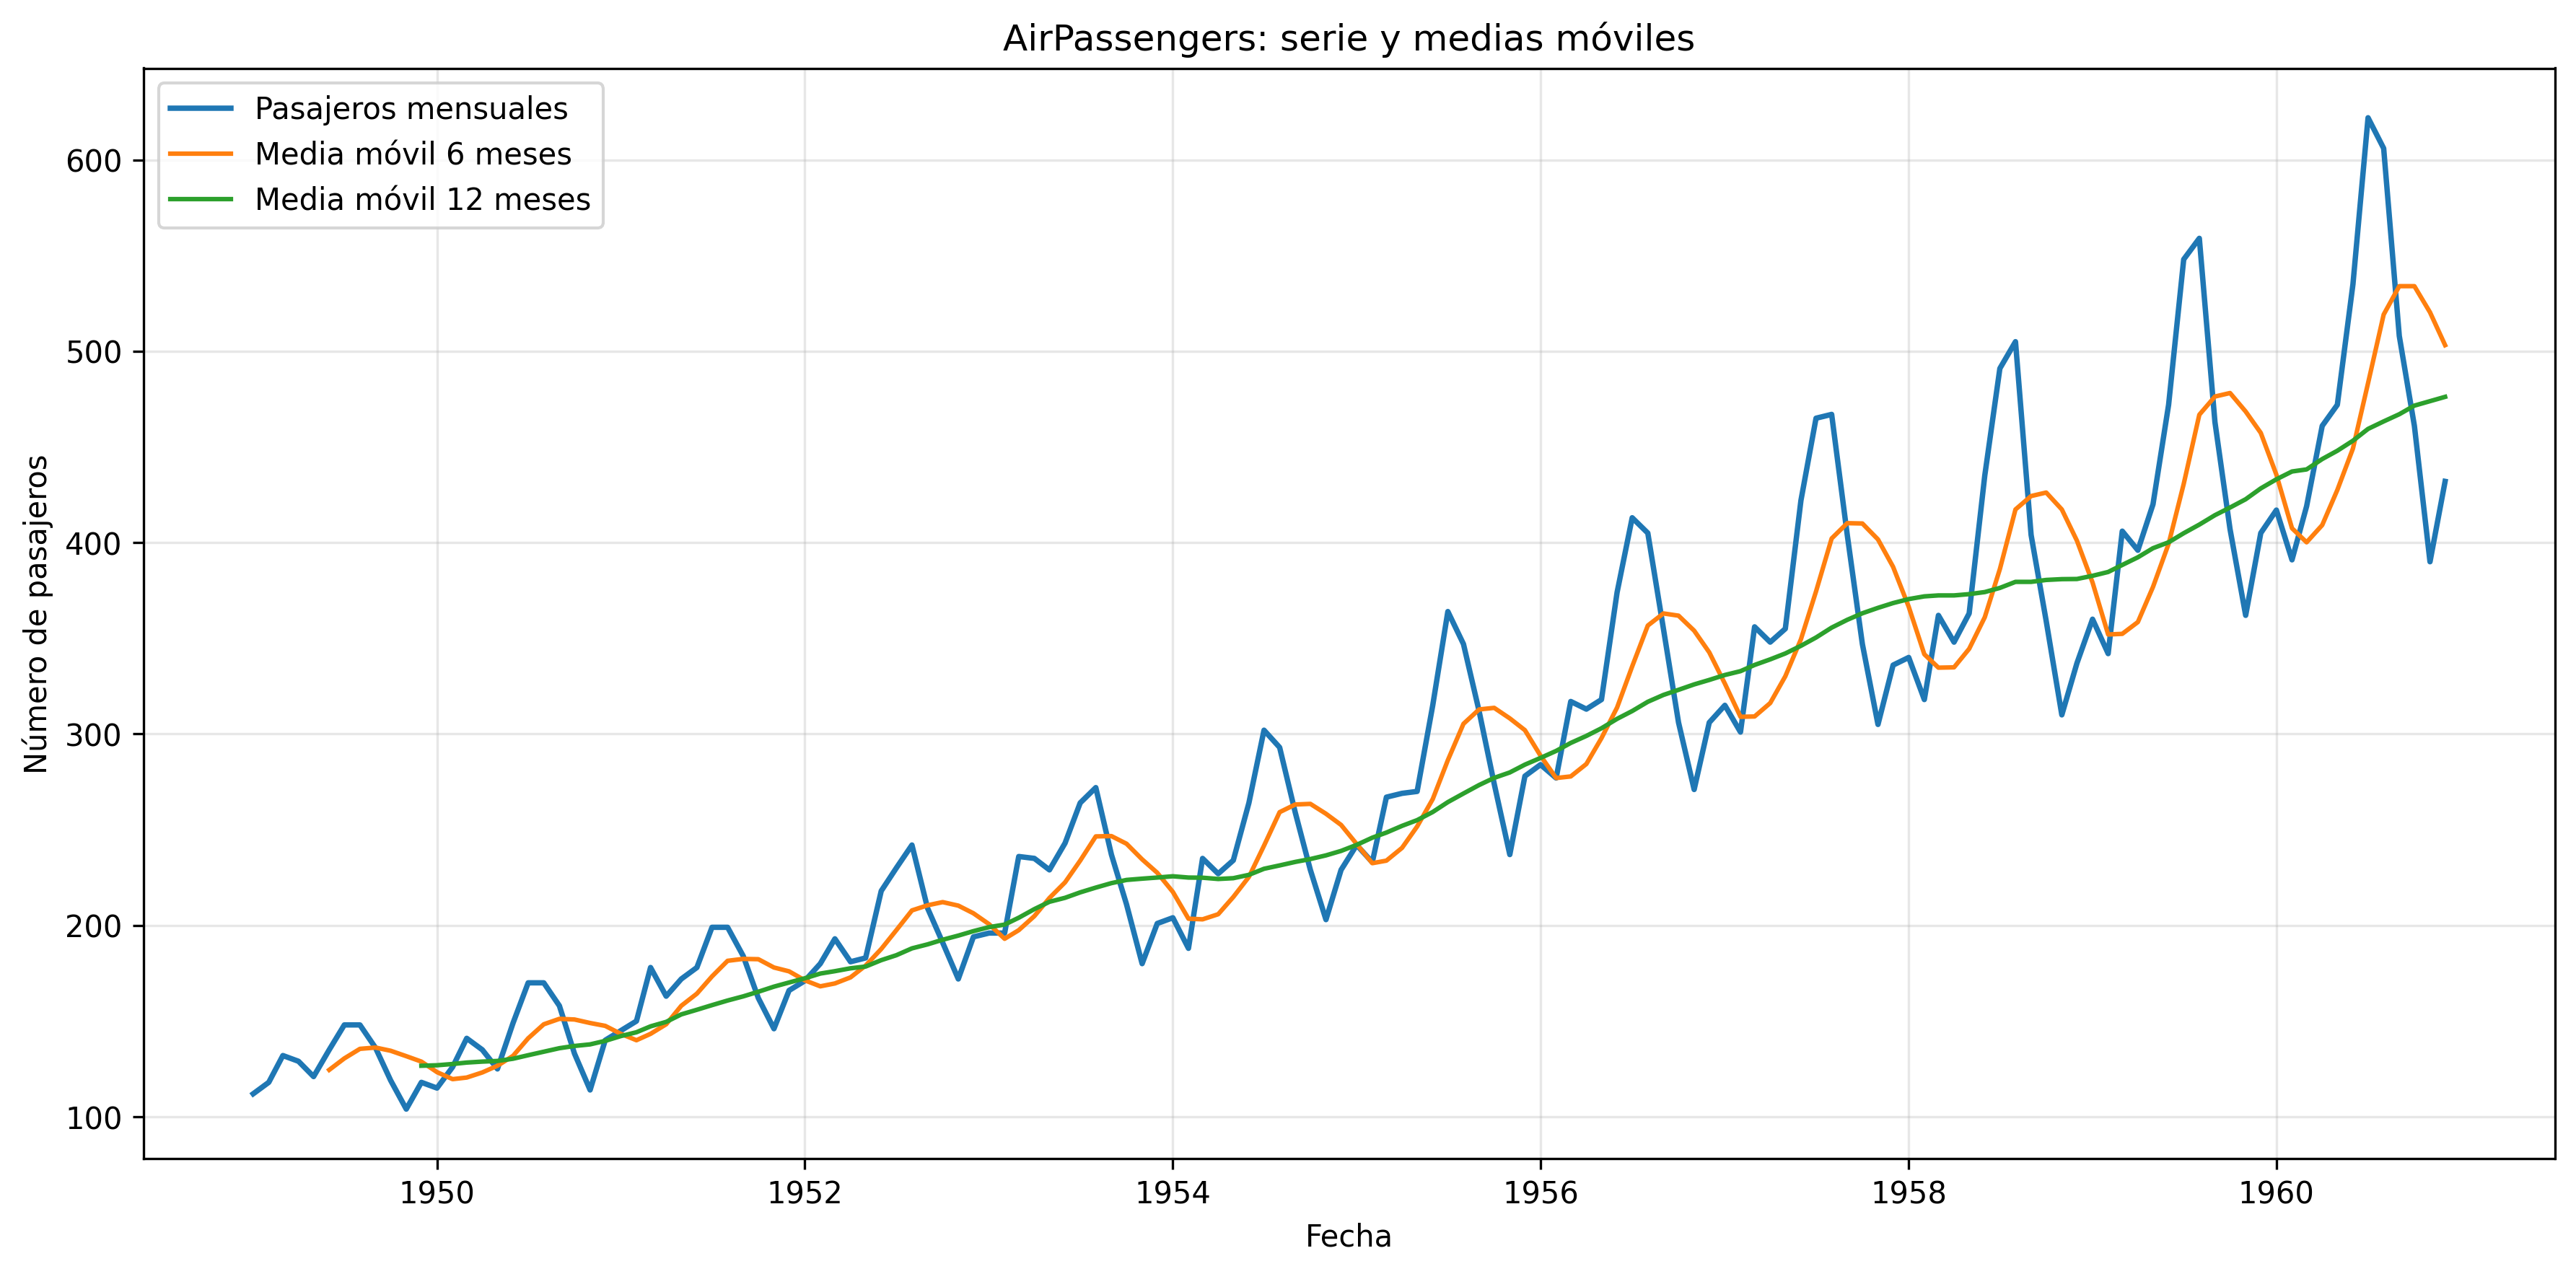

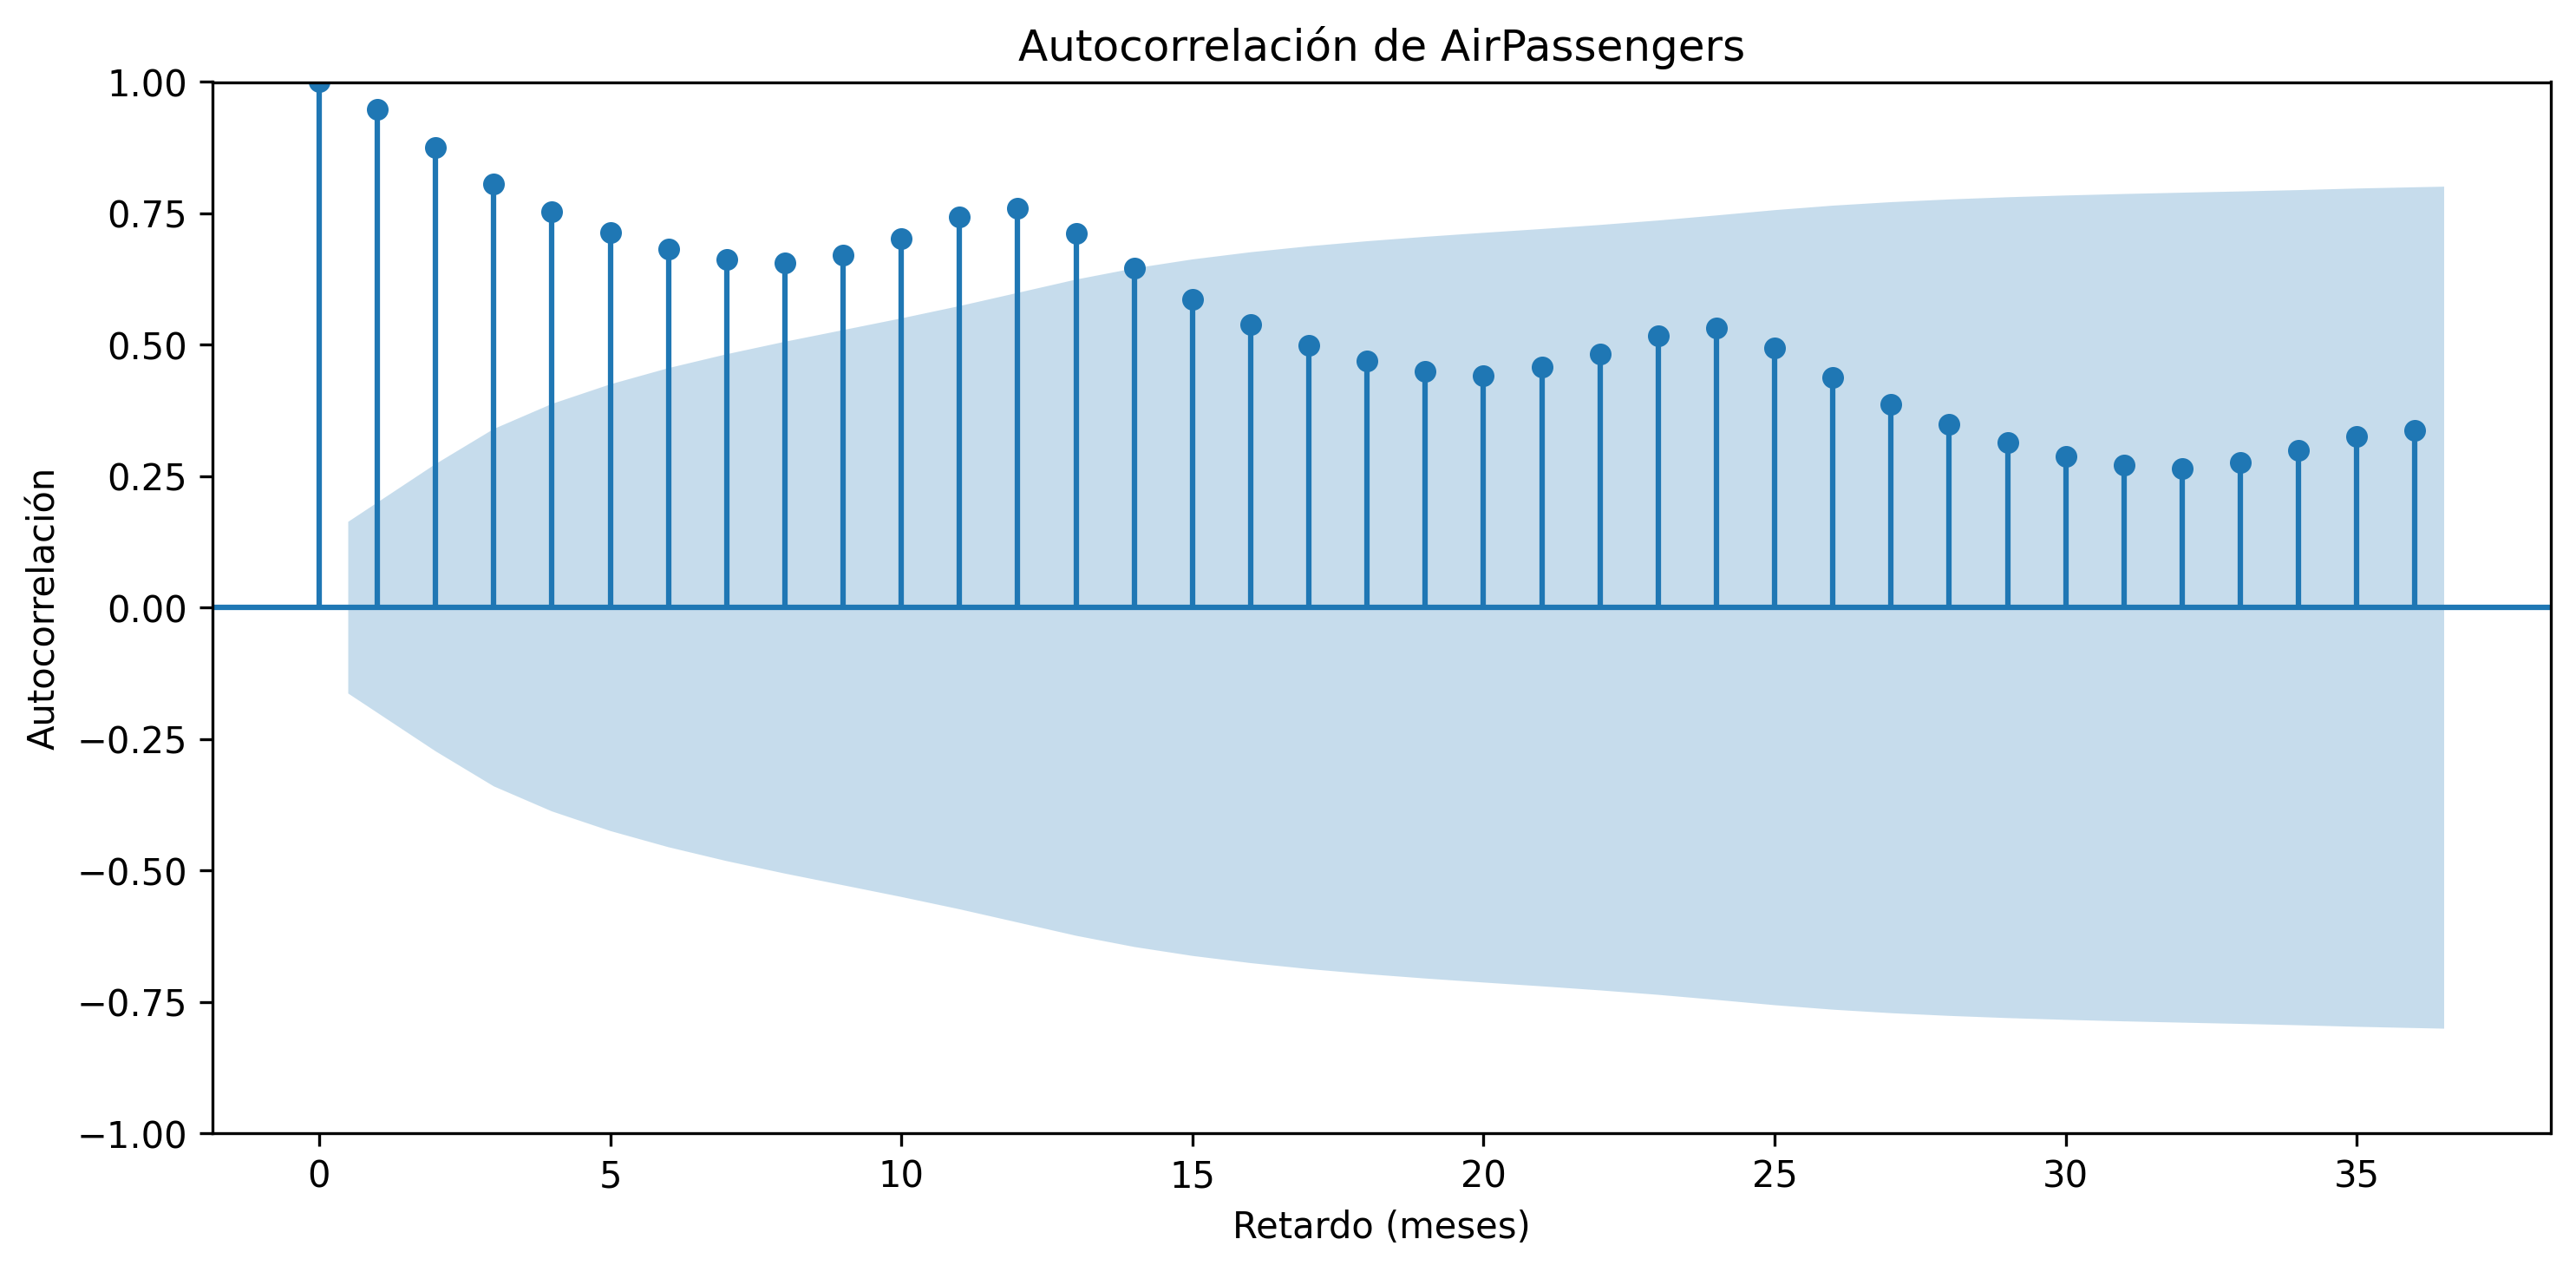

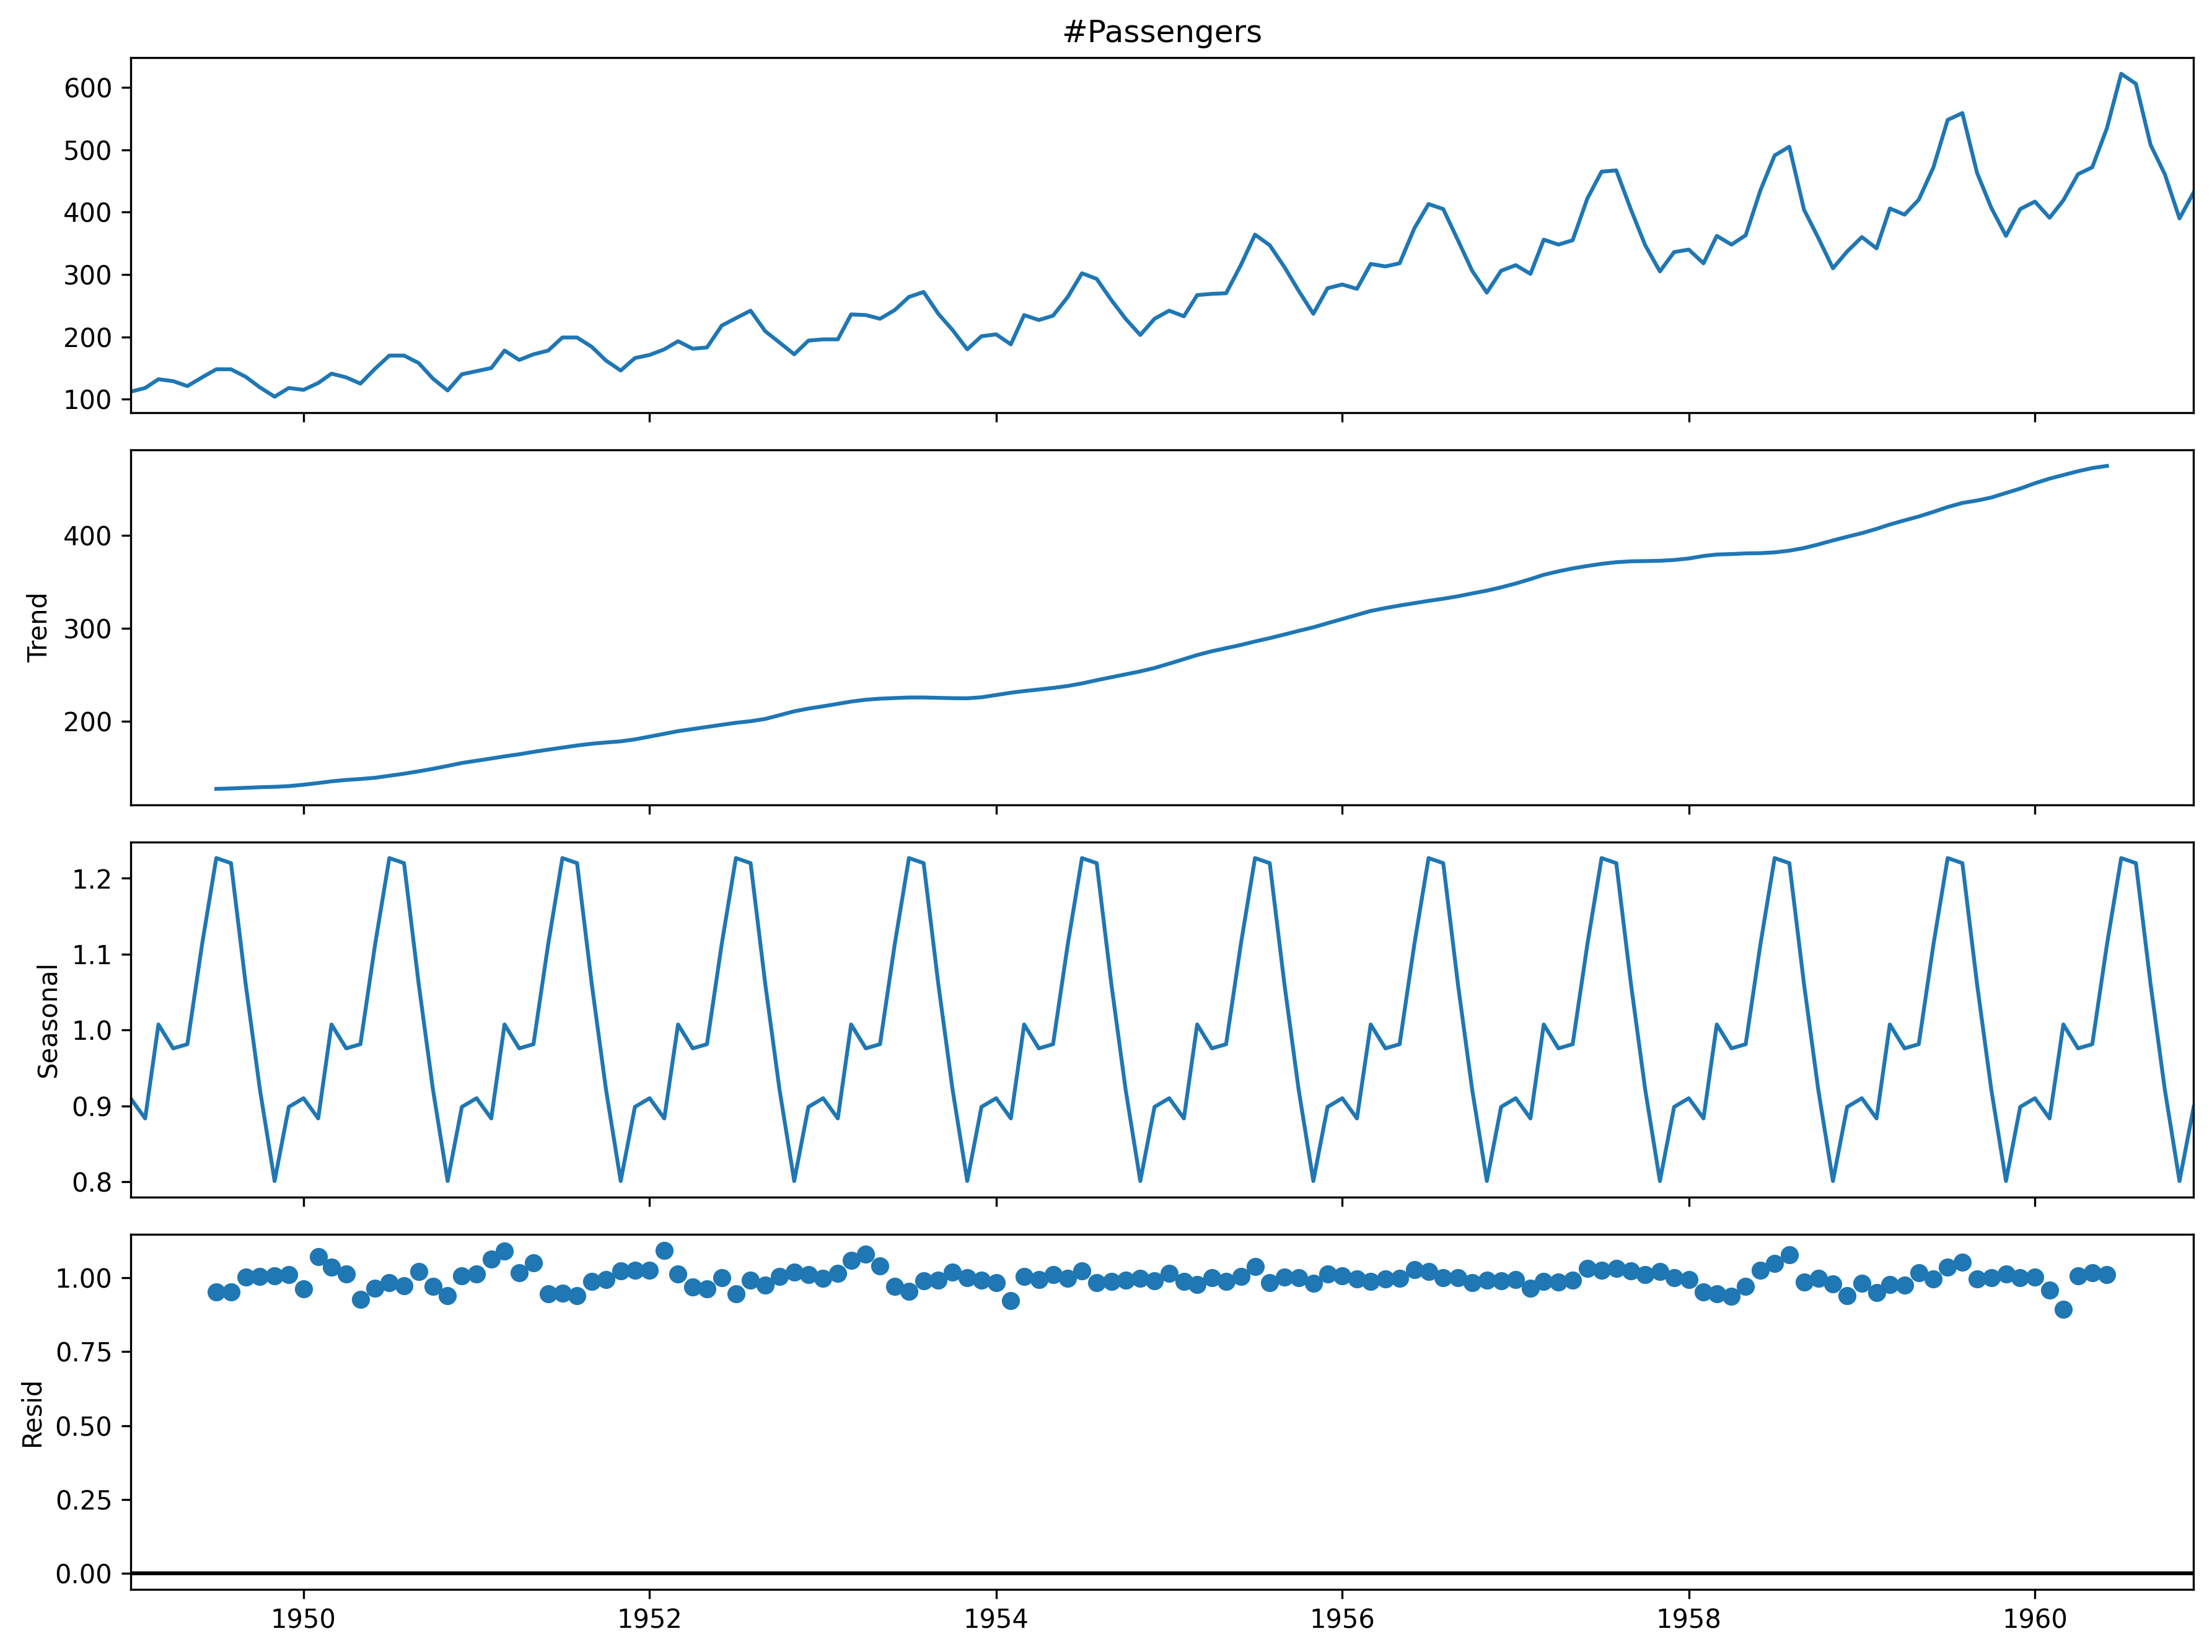

In [10]:
from IPython.display import display, Image
display(Image(filename="time_series_moving_average.png"))
display(Image(filename="time_series_autocorrelation.png"))
display(Image(filename="time_series_decomposition.png"))

### Estacionariedad y pronóstico
La prueba ADF se utiliza como apoyo cuantitativo para evaluar la estacionariedad. Para el pronóstico se reservan los últimos 24 meses como periodo de prueba y se ajusta Holt-Winters con tendencia aditiva y estacionalidad multiplicativa de 12 meses. La comparación con los valores reales permite evaluar el comportamiento del pronóstico mediante MSE y R².

In [11]:
forecast_results = time_series_results["forecast"]
pd.DataFrame({
    "Métrica": ["Periodo de prueba", "MSE", "R²"],
    "Resultado": [
        f"{len(forecast_results['test'])} meses",
        f"{forecast_results['mse']:.4f}",
        f"{forecast_results['r2']:.4f}",
    ],
})

,Métrica,Resultado
0,Periodo de prueba,24 meses
1,MSE,1055.5099
2,R²,0.8107


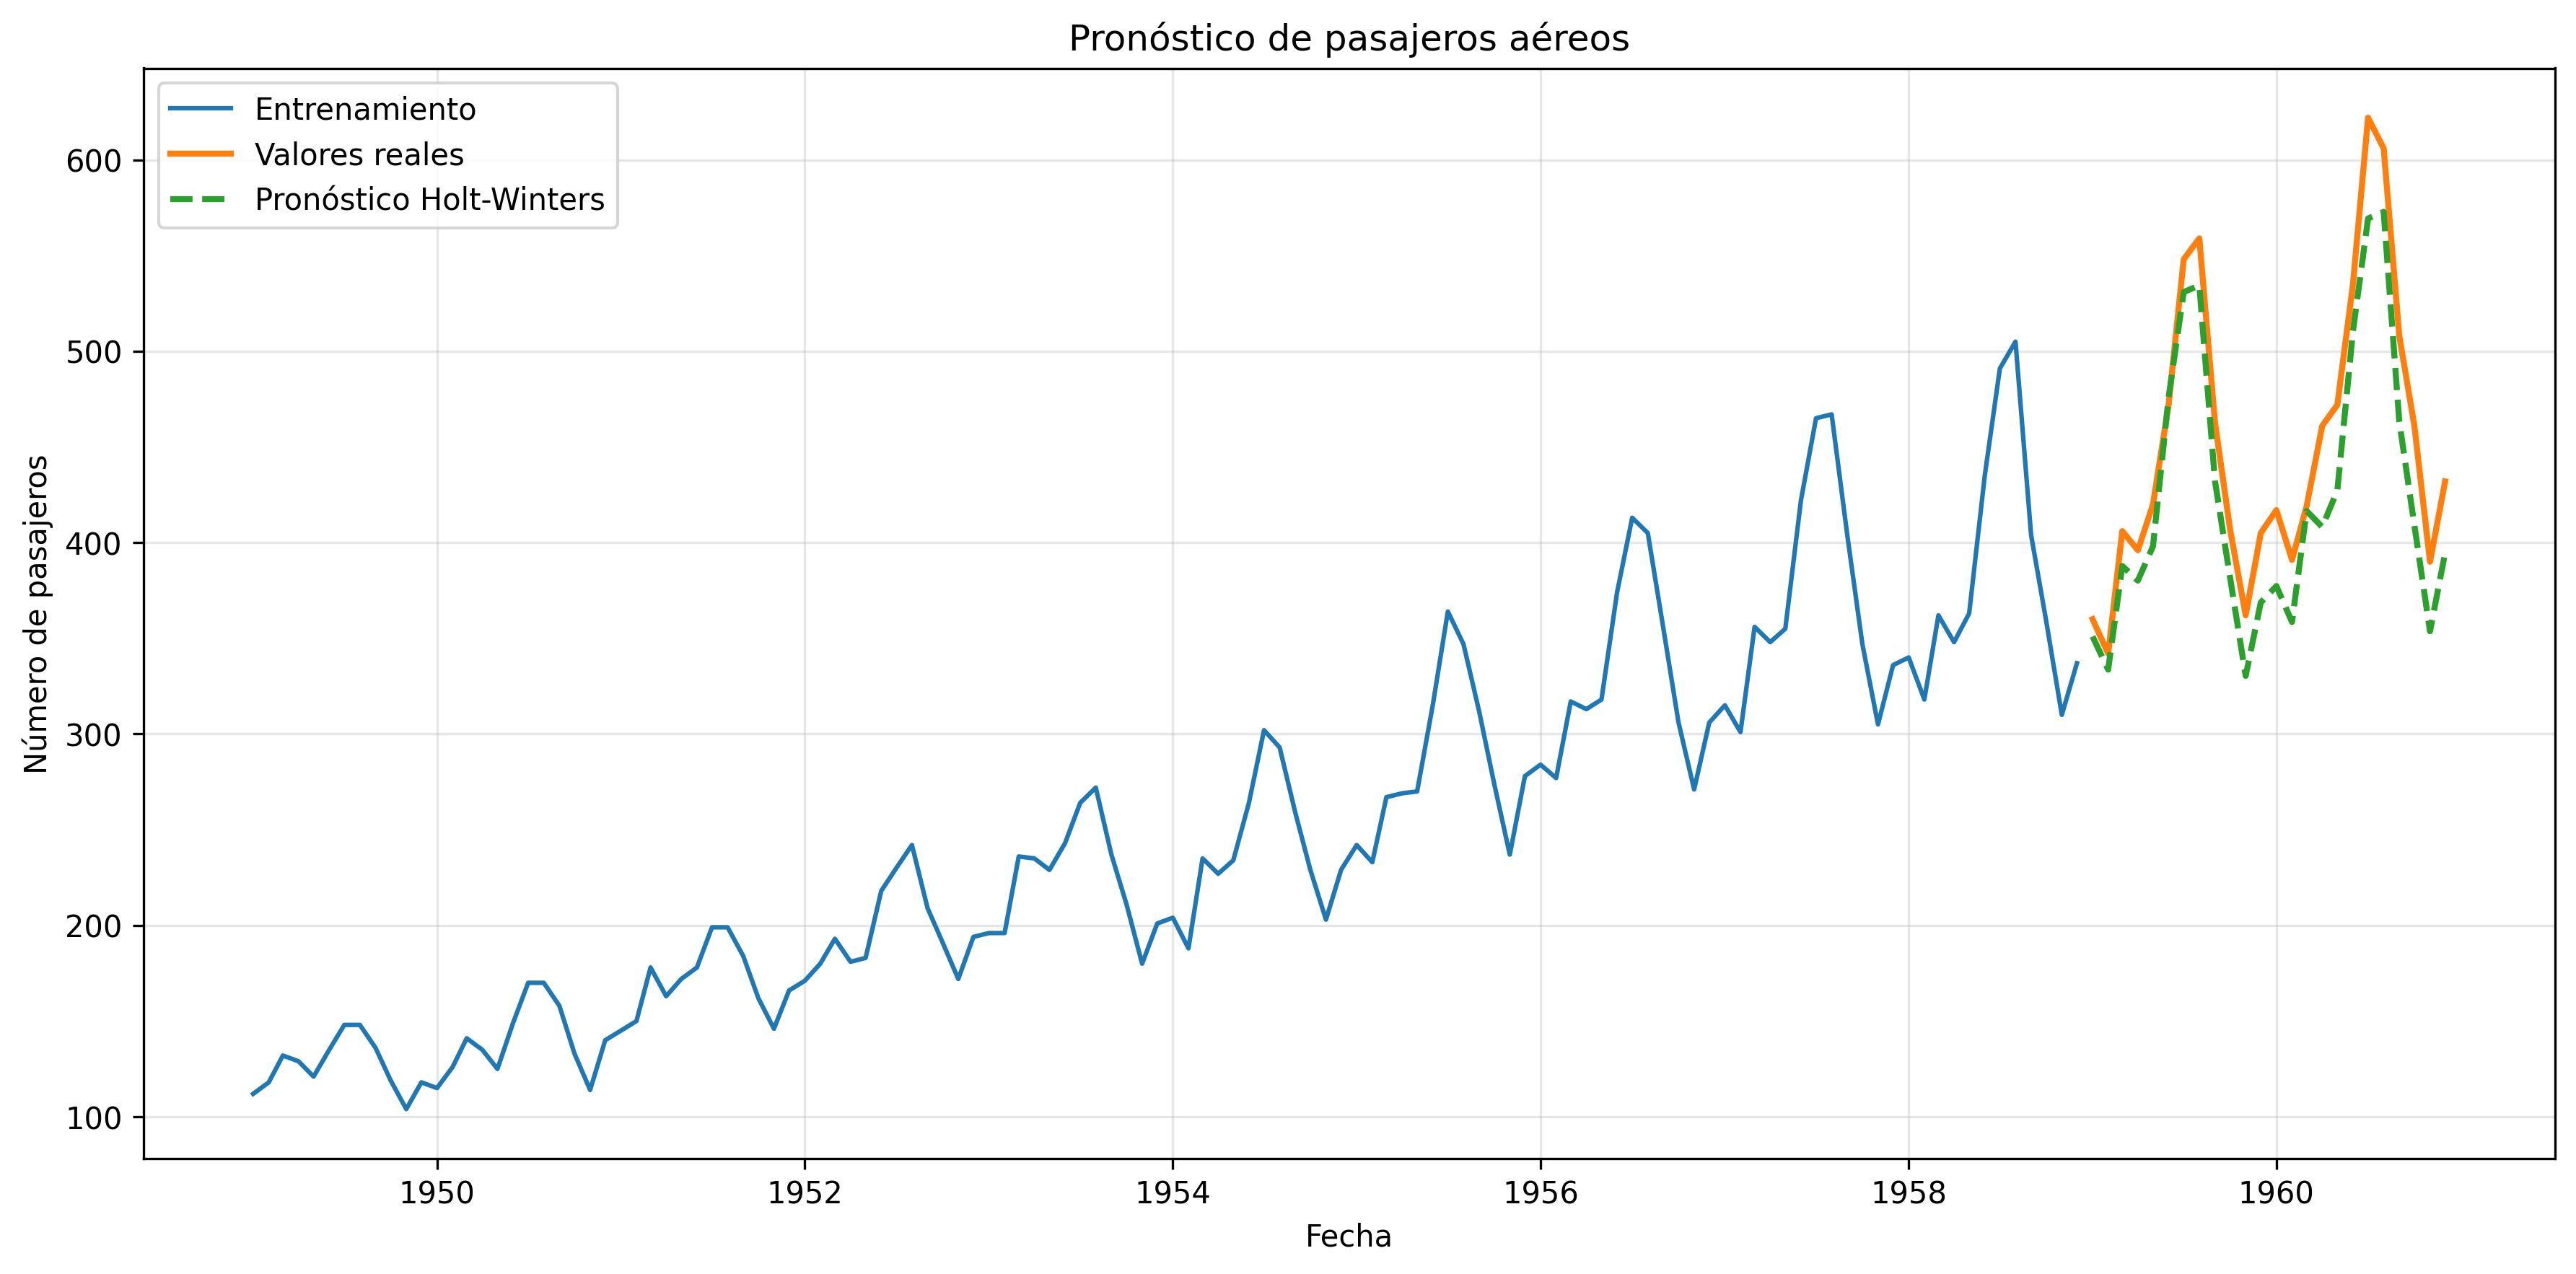

In [12]:
from IPython.display import display, Image
display(Image(filename="time_series_forecast.png"))

## 5. Preguntas de análisis

### 5.1 ¿Qué ventajas ofrece la regresión polinomial frente a la lineal? ¿Cuáles son sus riesgos?
La regresión polinomial ofrece mayor flexibilidad para representar relaciones no lineales mediante términos como X² y X³. En este ejercicio los modelos polinomiales mejoran claramente el desempeño del modelo lineal. Sin embargo, aumentar excesivamente el grado puede producir sobreajuste al representar también el ruido presente en los datos.

### 5.2 ¿Por qué es importante estandarizar los datos antes de aplicar clustering?
La estandarización lleva las variables a escalas comparables y reduce el riesgo de que una característica con mayor magnitud o variabilidad domine las distancias utilizadas por los algoritmos. En este ejercicio, ingreso anual y puntuación de gasto se estandarizan antes de aplicar K-Means y DBSCAN.

### 5.3 ¿Qué patrones temporales se observan? ¿Qué modelo podría mejorar o contrastar la predicción?
AirPassengers presenta tendencia creciente, estacionalidad anual y fuerte dependencia temporal. La amplitud de las oscilaciones aumenta con el nivel de la serie, por lo que se utilizó estacionalidad multiplicativa en Holt-Winters. Como alternativa para contrastar el pronóstico podría evaluarse un modelo SARIMA y comparar su desempeño sobre el mismo periodo de prueba.

### 5.4 Casos reales de aplicación
- **Regresión lineal:** estimar una variable cuando la relación con los predictores es aproximadamente lineal, por ejemplo consumo frente a producción.
- **Regresión polinomial:** modelar relaciones curvas, como consumo energético frente a temperatura.
- **K-Means:** segmentar clientes según características de comportamiento o valor.
- **DBSCAN:** identificar concentraciones naturales y observaciones aisladas, por ejemplo en datos geográficos.
- **Holt-Winters:** pronosticar series con tendencia y estacionalidad, como ventas o demanda mensual.

## 6. Conclusiones

La actividad permite observar que la elección del método depende de la estructura de los datos y del objetivo del análisis. La regresión polinomial mejora el ajuste cuando existe una relación no lineal; K-Means y DBSCAN producen segmentaciones desde criterios diferentes; y el análisis temporal requiere considerar explícitamente el orden, la tendencia, la estacionalidad y la dependencia entre observaciones.

En AirPassengers, Holt-Winters permite construir un pronóstico a partir de tendencia y estacionalidad, mientras las métricas calculadas sobre un periodo reservado facilitan evaluar su capacidad de generalización temporal. En conjunto, los ejercicios muestran la importancia de combinar resultados numéricos, visualizaciones e interpretación antes de seleccionar o comparar modelos.